# 1. Downloading MICrONS

The code below will download parts of the MICrONS database that we are interested in. Specifically, we're looking for:
- Neurons with calcium imaging data
- Neuron pairs that have proofread synapses

To do this, you need to get an API token for CAVE. Here's how you go about doing that:
1. Go to https://global.daf-apis.com/auth/api/v1/create_token to create a new token
2. Log in with your Google credentials and copy the token shown afterward
3. Paste your token into the `.env` file (you create yourself) under `TOKEN=`

In [1]:
%pip install -U caveclient dandi pynwb h5py fsspec h5py pandas numpy python-dotenv

  Using cached pandas-3.1.0-cp313-cp313-macosx_11_0_arm64.whl.metadata (18 kB)

[notice] A new release of pip is available: 24.2 -> 26.2.1
[notice] To update, run: pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


In [2]:
import os
from dotenv import load_dotenv
from caveclient import CAVEclient

load_dotenv()

client = CAVEclient(
    datastack_name="minnie65_public",
    version=1926,
    auth_token=os.getenv("TOKEN"),
)

print(f"cwd:  {os.getcwd()}")
print(f"home: {os.path.expanduser("~")}")
print(f".:    {os.listdir(".")}")

NEURONS_REGEN = False
SYNAPSES_REGEN = False
FUNCTIONAL_REGEN = False
DISTANCE_BENCH = False


cwd:  /Users/jeffrey/projects/UCB/NTAB/NTAB_F26_Connectomics/jeffrey
home: /Users/jeffrey
.:    ['.DS_Store', 'cache', 'scratch.ipynb', 'official.ipynb', '.env']


# 2. Construct Neuron Lookup

We are going to build `neurons_df`, a general-purpose neuron information lookup. Here are the table headers:

| Key | Type | Description |
| - | - | - |
| `id` | `int` | INDEX |
| `cell_class` | `str` | `none` or `excitatory` or `inhibitory` |
| `cell_type` | `str` | `none` or a ton of different things provided by MICrONS |
| `axon_proof` | `str` | `none` or the specified proofread value |
| `dend_proof` | `str` | `none` or the specified proofread value |
| `x` | `float` | cell body position, in microns |
| `y` | `float` | cell body position, in microns |
| `z` | `float` | cell body position, in microns |

To access calcium traces, you must use a custom function, as it will construct the `Trace` objects.

In [3]:
raw_coreg_df = client.materialize.query_table(
    "coregistration_manual_v4",
    desired_resolution=[1]*3,
    split_positions=True,
)
raw_coreg_df = raw_coreg_df[raw_coreg_df["valid"] == True]
raw_coreg_df.set_index("pt_root_id", inplace=True)
raw_coreg_df.rename_axis("id", inplace=True)
raw_coreg_df.drop(index=0, inplace=True, errors="ignore")
print(raw_coreg_df.columns.to_list())
display(raw_coreg_df.head())


['id', 'created', 'valid', 'target_id', 'session', 'scan_idx', 'unit_id', 'field', 'residual', 'score', 'id_ref', 'created_ref', 'valid_ref', 'volume', 'pt_position_x', 'pt_position_y', 'pt_position_z', 'bb_start_position_x', 'bb_start_position_y', 'bb_start_position_z', 'bb_end_position_x', 'bb_end_position_y', 'bb_end_position_z', 'pt_supervoxel_id']


,id,created,valid,target_id,session,scan_idx,unit_id,field,residual,score,...,pt_position_x,pt_position_y,pt_position_z,bb_start_position_x,bb_start_position_y,bb_start_position_z,bb_end_position_x,bb_end_position_y,bb_end_position_z,pt_supervoxel_id
id,,,,,,,,,,,,,,,,,,,,,
864691135686521271,10490,2024-05-21 18:42:39.170710+00:00,True,224395,7,3,2398,2,7.02217,-1.39408,...,599360,532608,903680,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,85366977140498420
864691135686521271,19021,2024-05-21 18:42:43.833831+00:00,True,224395,9,6,4843,4,9.55213,5.02637,...,599360,532608,903680,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,85366977140498420
864691135565621079,5389,2024-05-21 18:38:25.314947+00:00,True,488652,6,2,5317,4,4.87698,5.54952,...,1150144,569856,775280,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,104297405805551073
864691135661411312,4173,2024-05-21 18:38:24.630120+00:00,True,559491,5,7,7100,6,3.27848,9.37382,...,1283584,697984,1061520,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,108875704443621534
864691136602371025,10449,2024-05-21 18:42:39.148608+00:00,True,553321,7,3,2288,2,3.79473,10.67347,...,1300864,482432,810320,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,109501806790703496


In [4]:
if NEURONS_REGEN:

    raw_proof_df = client.materialize.query_table(
        "proofreading_status_and_strategy",
        desired_resolution=[1]*3,
        split_positions=True,
    )
    raw_proof_df = raw_proof_df[raw_proof_df["valid"] == True]
    raw_proof_df.drop_duplicates(subset="pt_root_id", keep="first", inplace=True)
    raw_proof_df.set_index("pt_root_id", inplace=True)
    raw_proof_df.rename_axis("id", inplace=True)
    raw_proof_df.drop(index=0, inplace=True, errors="ignore")
    print(raw_proof_df.columns.to_list())
    display(raw_proof_df.head())
    
    # confirm that if status_* is False, then strategy_* is "none" so that we can just use strategy_*
    for compartment in ["dendrite", "axon"]:
        status = raw_proof_df[f"status_{compartment}"]
        strategy = raw_proof_df[f"strategy_{compartment}"]
        exceptions = raw_proof_df[(~status.fillna(False)) & strategy.ne("none")]
        print(f"{compartment} exceptions: {len(exceptions)}")

else:

    print("Skip! We're using volume")


Skip! We're using volume


In [5]:
if NEURONS_REGEN:

    raw_celltype_df = client.materialize.query_table(
        "aibs_metamodel_celltypes_v661",
        desired_resolution=[1]*3,
        split_positions=True,
    )
    raw_celltype_df = raw_celltype_df[raw_celltype_df["valid"] == True]
    raw_celltype_df.drop_duplicates(subset="pt_root_id", keep="first", inplace=True)
    raw_celltype_df.set_index("pt_root_id", inplace=True)
    raw_celltype_df.rename_axis("id", inplace=True)
    raw_celltype_df.drop(index=0, inplace=True, errors="ignore")
    print(raw_celltype_df.columns.to_list())
    display(raw_celltype_df.head())

else:

    print("Skip! We're using volume")


Skip! We're using volume


In [6]:
import os
from dataclasses import dataclass
import pandas as pd

@dataclass(frozen=True)
class Trace:
    session: int
    scan_idx: int
    unit_id: int

if NEURONS_REGEN:
    
    ids = list(set(raw_coreg_df.index.to_list())) # [:10000]
    
    cell_class_type_df = (
        raw_celltype_df[["classification_system", "cell_type"]]
        .reindex(ids, fill_value="none")
    )
    cell_class_type_df.rename(columns={
        "classification_system": "cell_class",
    }, inplace=True)
    cell_class_type_df["cell_class"] = cell_class_type_df["cell_class"].replace({
        "excitatory_neuron": "excitatory",
        "inhibitory_neuron": "inhibitory",
    })
    
    axon_dend_proof_df = (
        raw_proof_df[["strategy_axon", "strategy_dendrite"]]
        .reindex(ids, fill_value="none")
    )
    axon_dend_proof_df.rename(columns={
        "strategy_axon": "axon_proof",
        "strategy_dendrite": "dend_proof",
    }, inplace=True)
    
    position_df = (
        raw_coreg_df
        [~raw_coreg_df.index.duplicated(keep='first')]
        [["pt_position_x", "pt_position_y", "pt_position_z"]]
        .reindex(ids)
    )
    position_df.rename(columns={
        "pt_position_x": "x",
        "pt_position_y": "y",
        "pt_position_z": "z",
    }, inplace=True)
    position_df[["x", "y", "z"]] = (position_df[["x", "y", "z"]] / 1e3).apply(pd.to_numeric, errors="coerce") # nm → µm
    
    print(position_df.isna().sum()) # this should all be zeroes!!

    neurons_df = pd.concat([cell_class_type_df, axon_dend_proof_df, position_df], axis=1)

else:

    neurons_df = pd.read_parquet("cache/mnt/neurons/neurons.parquet")

traces_by_neuron = raw_coreg_df.groupby(level="id")
def get_traces(neuron_id):
    group = traces_by_neuron.get_group(neuron_id)
    return [
        Trace(
            session=row.session,
            scan_idx=row.scan_idx,
            unit_id=row.unit_id,
        )
        for row in group.itertuples()
    ]

print(neurons_df.columns.to_list())
print(neurons_df.shape)
display(neurons_df.head())

if NEURONS_REGEN:
    os.makedirs("cache/neurons", exist_ok=True)
    neurons_df.to_parquet("cache/neurons/neurons.parquet")


['cell_class', 'cell_type', 'axon_proof', 'dend_proof', 'x', 'y', 'z']
(15433, 7)


,cell_class,cell_type,axon_proof,dend_proof,x,y,z
id,,,,,,,
864691135939903489,excitatory,23P,none,none,662.208,433.216,1013.68
864691134918524938,inhibitory,BPC,none,none,859.712,744.064,1001.68
864691135293882380,excitatory,5P-IT,none,none,1352.384,660.864,1079.16
864691136274759693,excitatory,23P,none,none,943.808,561.792,1054.16
864691136238845967,excitatory,5P-IT,axon_partially_extended,dendrite_extended,934.016,735.488,899.56


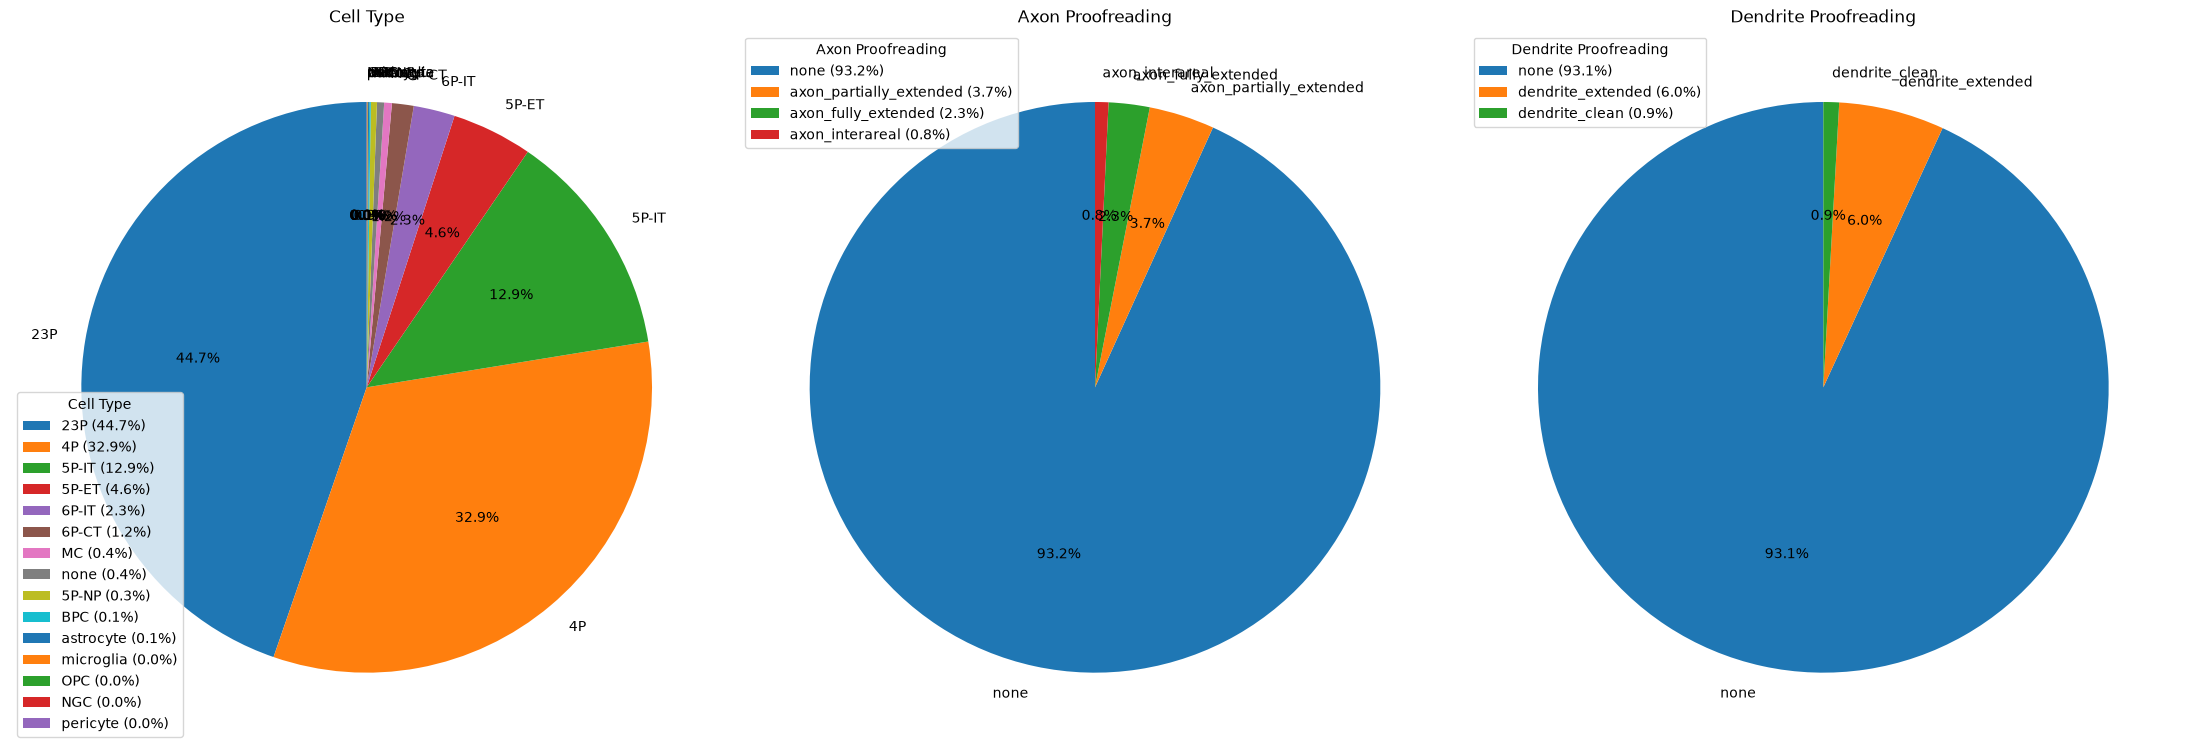

In [7]:
import matplotlib.pyplot as plt

cell_type_p = neurons_df["cell_type"].value_counts(normalize=True) * 100
axon_proof_p = neurons_df["axon_proof"].value_counts(normalize=True) * 100
dend_proof_p = neurons_df["dend_proof"].value_counts(normalize=True) * 100

fig, axes = plt.subplots(1, 3, figsize=(22, 8))

neurons_df["cell_type"].fillna("none").astype(str).value_counts().plot.pie(
    ax=axes[0],
    ylabel="",
    autopct="%1.1f%%",
    startangle=90,
)
axes[0].set_title("Cell Type")
handles, labels = axes[0].get_legend_handles_labels()
axes[0].legend(
    handles,
    [f"{label} ({cell_type_p.get(label, 0):.1f}%)" for label in labels],
    title="Cell Type",
)

neurons_df["axon_proof"].fillna("none").value_counts().plot.pie(
    ax=axes[1],
    ylabel="",
    autopct="%1.1f%%",
    startangle=90,
)
axes[1].set_title("Axon Proofreading")
handles, labels = axes[1].get_legend_handles_labels()
axes[1].legend(
    handles,
    [f"{label} ({axon_proof_p.get(label, 0):.1f}%)" for label in labels],
    title="Axon Proofreading",
)

neurons_df["dend_proof"].fillna("none").value_counts().plot.pie(
    ax=axes[2],
    ylabel="",
    autopct="%1.1f%%",
    startangle=90,
)
axes[2].set_title("Dendrite Proofreading")
handles, labels = axes[2].get_legend_handles_labels()
axes[2].legend(
    handles,
    [f"{label} ({dend_proof_p.get(label, 0):.1f}%)" for label in labels],
    title="Dendrite Proofreading",
)

plt.tight_layout()
plt.show()

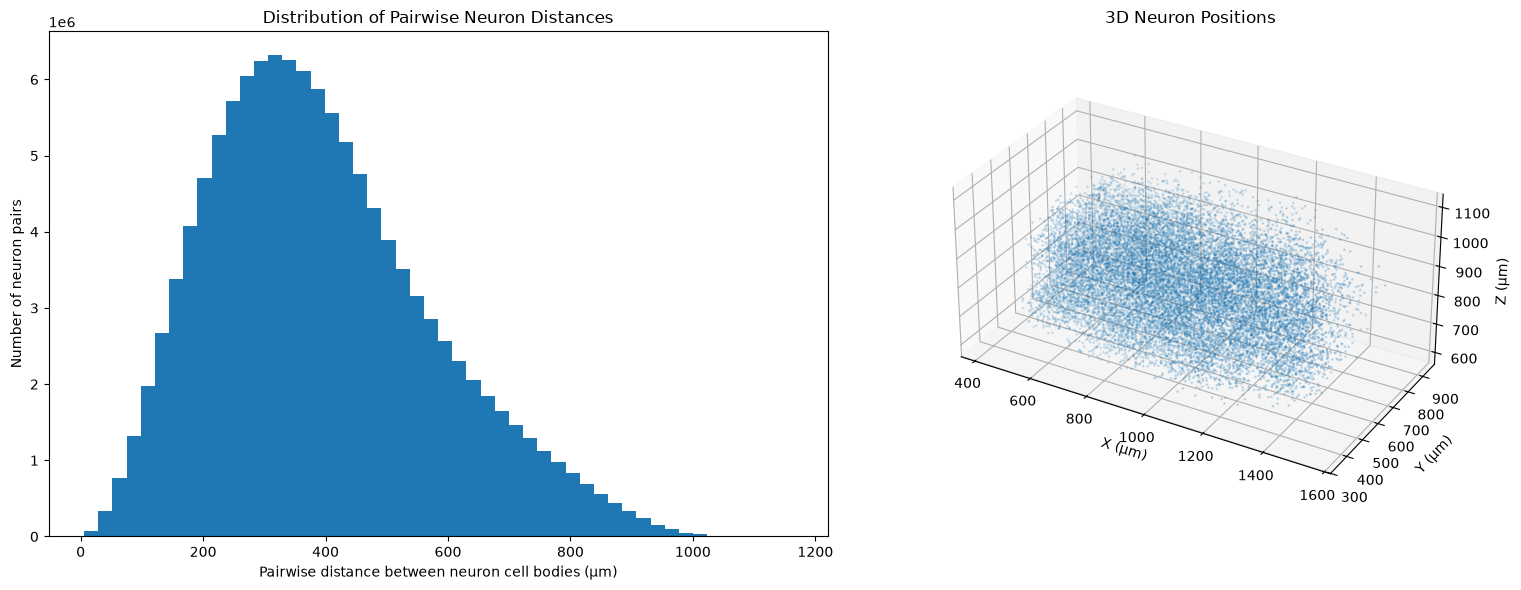

In [8]:
import matplotlib.pyplot as plt
from scipy.spatial.distance import pdist

positions_df = neurons_df[["x", "y", "z"]].dropna()
positions = positions_df.to_numpy(dtype=float)

distances = pdist(positions, metric="euclidean")

fig = plt.figure(figsize=(16, 6))

ax1 = fig.add_subplot(121)
ax1.hist(distances, bins=50)

ax1.set_xlabel("Pairwise distance between neuron cell bodies (µm)")
ax1.set_ylabel("Number of neuron pairs")
ax1.set_title("Distribution of Pairwise Neuron Distances")

ax2 = fig.add_subplot(122, projection="3d")
ax2.scatter(
    positions[:, 0],
    positions[:, 1],
    positions[:, 2],
    s=1,
    alpha=0.5,
)

ax2.set_xlabel("X (µm)")
ax2.set_ylabel("Y (µm)")
ax2.set_zlabel("Z (µm)")
ax2.set_title("3D Neuron Positions")

ax2.set_box_aspect([
    positions[:, 0].max() - positions[:, 0].min(),
    positions[:, 1].max() - positions[:, 1].min(),
    positions[:, 2].max() - positions[:, 2].min(),
])

plt.tight_layout()
plt.show()

# 3. Construct Synapse Lookup

We are going to build `synapses_df`, a general-purpose synapse information lookup. Here are the table headers:
| Key | Type | Description |
| - | - | - |
| `pre_id` | `int` | INDEX, the presynaptic neuron id |
| `post_id` | `int` | INDEX, the postsynaptic neuron id |
| `n` | `int` | the number of synapses, usable as the "strength" of a connection |

In [9]:
import os
import math

BATCH_SIZE = 100

if SYNAPSES_REGEN:

    ids = neurons_df.index.to_list()
    
    cache_dir = f"cache/synapses/n{neurons_df.shape[0]}_bs{BATCH_SIZE}"
    os.makedirs(cache_dir, exist_ok=True)
    
    n_batches = math.ceil(neurons_df.shape[0] / BATCH_SIZE)
    for batch_i in range(n_batches):
        file = os.path.join(cache_dir, f"b{batch_i}.parquet")
        if os.path.exists(file):
            print(f"Fetching batch {batch_i}/{n_batches}: SKIPPED, exists")
            continue
        start = batch_i * BATCH_SIZE
        stop = min((batch_i + 1) * BATCH_SIZE, neurons_df.shape[0])
        print(f"Fetching batch {batch_i}/{n_batches}: [{start}, {stop})...")
        pre_ids = ids[start:stop]
        post_ids = ids
        batch_df = client.materialize.synapse_query(
            pre_ids=pre_ids,
            post_ids=post_ids,
            remove_autapses=True,
            desired_resolution=[1]*3,
            split_positions=True,
        )
        batch_df.to_parquet(file)
        print(f"Fetched batch {batch_i}")
    
    batch_dfs = []
    for batch_i in range(n_batches):
        batch_df = pd.read_parquet(os.path.join(cache_dir, f"b{batch_i}.parquet"))
        batch_dfs.append(batch_df)
    
    raw_synapses_df = pd.concat(batch_dfs, axis=0)
    print(raw_synapses_df.columns.to_list())
    display(raw_synapses_df.head())

else:
    
    print("Skip! We're using volume")

Skip! We're using volume


In [10]:
import pandas as pd

if SYNAPSES_REGEN:
    
    synapses_df = (
        raw_synapses_df
        .groupby(["pre_pt_root_id", "post_pt_root_id"])
        .size()
        .rename("n")
        .to_frame()
    )
    synapses_df.index.names = ["pre_id", "post_id"]
    
else:
    
    synapses_df = pd.read_parquet("cache/mnt/synapses/synapses.parquet")

print(synapses_df.columns.to_list())
print(synapses_df.shape)
display(synapses_df.head())

if SYNAPSES_REGEN:
    synapses_df.to_parquet("cache/synapses/synapses.parquet")

['n']
(480030, 1)


n
pre_id             post_id              
864691134884756730 864691135059358875  2
                   864691135210864064  1
                   864691135213620864  1
                   864691135441512776  1
                   864691135479370694  1

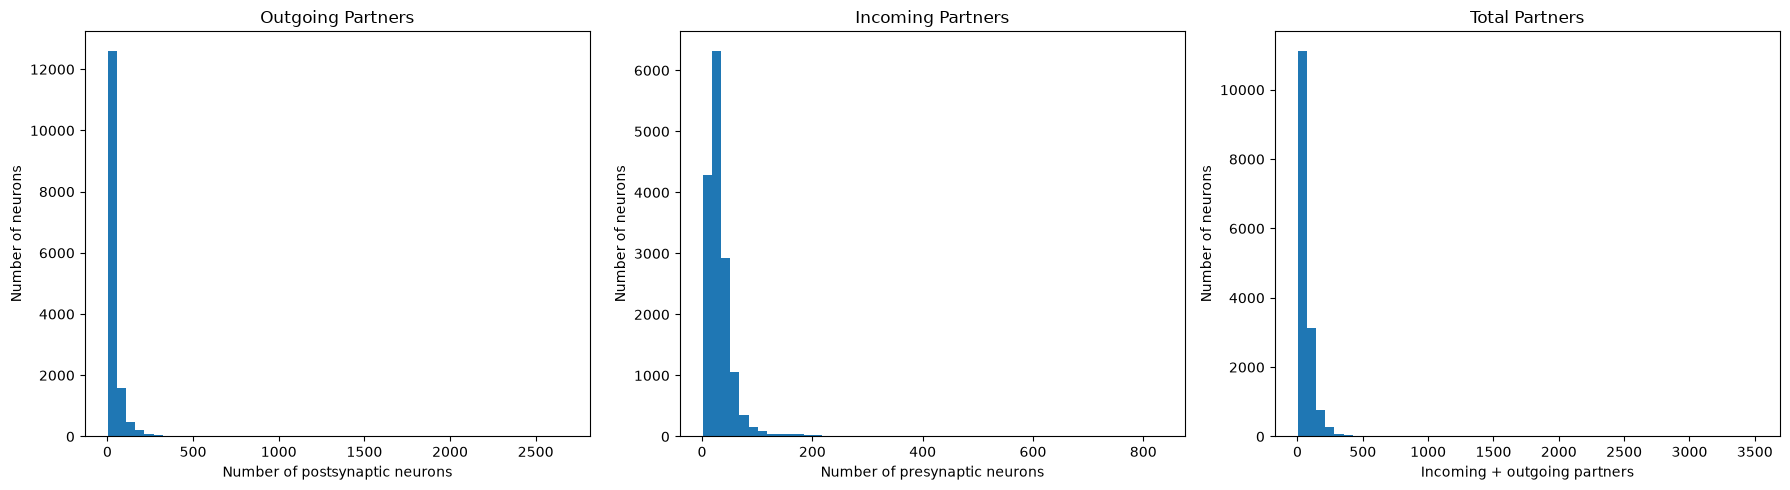

In [11]:
import matplotlib.pyplot as plt

pairs = synapses_df.reset_index()
posts_per_pre = pairs.groupby("pre_id")["post_id"].nunique()
pres_per_post = pairs.groupby("post_id")["pre_id"].nunique()
total_connections = posts_per_pre.add(pres_per_post, fill_value=0)

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

axes[0].hist(posts_per_pre, bins=50)
axes[0].set_xlabel("Number of postsynaptic neurons")
axes[0].set_ylabel("Number of neurons")
axes[0].set_title("Outgoing Partners")

axes[1].hist(pres_per_post, bins=50)
axes[1].set_xlabel("Number of presynaptic neurons")
axes[1].set_ylabel("Number of neurons")
axes[1].set_title("Incoming Partners")

axes[2].hist(total_connections, bins=50)
axes[2].set_xlabel("Incoming + outgoing partners")
axes[2].set_ylabel("Number of neurons")
axes[2].set_title("Total Partners")

plt.tight_layout()
plt.show()

# 4. Construct Functional Lookup

We are going to build `functional_df`, a general-purpose functional connection information lookup. Here are the table headers:
| Key | Type | Description |
| - | - | - |
| `pre_id` | int | INDEX, the presynaptic neuron id |
| `post_id` | int | INDEX, the postsynaptic neuron id |
| `strength` | float | the strength of a connection |

In [12]:
# TODO: actually get the data downloaded and usable soon™

if FUNCTIONAL_REGEN:
    
    functional_df = synapses_df.copy()
    functional_df.rename(columns={"n": "strength"}, inplace=True)
    
else:
    
    functional_df = pd.read_parquet("cache/mnt/functional/functional.parquet")

print(functional_df.columns.to_list())
print(functional_df.shape)
display(functional_df.head())

if FUNCTIONAL_REGEN:
    os.makedirs("cache/functional", exist_ok=True)
    functional_df.to_parquet("cache/functional/functional.parquet")

['strength']
(480030, 1)


strength
pre_id             post_id                     
864691134884756730 864691135059358875         2
                   864691135210864064         1
                   864691135213620864         1
                   864691135441512776         1
                   864691135479370694         1

# 5. Baselines

These different baselines let us compare how well our trained model performs.

## 5.1. Distance-matched Baseline

This is just to see how well a Euclidian distance-based fares against the whole dataset.

We have a couple considerations to make here.
1. Most neuron pairs are not synaptic. A high accuracy score could simply mean it classifies a lot of neurons as non-synaptic.
2. Distance-matched analysis is guaranteed to result in 50% accuracy, since the distance distributions match.

We will also create the distance-matching here.

In [13]:
import numpy as np
import pandas as pd
from scipy.spatial.distance import pdist

if DISTANCE_BENCH:
    
    ids_np = np.array(ids)
    
    positions_df = neurons_df[["x", "y", "z"]].dropna()
    positions = position_df.to_numpy(dtype=float)
    distances = pdist(positions, metric="euclidean")
    
    pair_i, pair_j = np.triu_indices(len(ids_np), k=1)
    pairs_df = pd.DataFrame({
        "id1": ids_np[pair_i],
        "id2": ids_np[pair_j],
        "distance": distances,
    })
    synapse_pairs = set(synapses_df.index.to_list())
    
    pairs_df["has_synapse"] = [
        (a, b) in synapse_pairs or (b, a) in synapse_pairs
        for a, b in zip(pairs_df["id1"], pairs_df["id2"])
    ]
    
    nonsyn_distances = pairs_df.loc[~pairs_df["has_synapse"], "distance"].to_numpy(dtype=float)
    syn_distances = pairs_df.loc[pairs_df["has_synapse"], "distance"].to_numpy(dtype=float)

In [14]:
if DISTANCE_BENCH:
    
    values = np.sort(np.unique(np.concatenate([syn_distances, nonsyn_distances])))
    thresholds = (values[:-1] + values[1:]) / 2
    
    syn_left = np.searchsorted(np.sort(syn_distances), thresholds, side="right") / len(syn_distances)
    nonsyn_right = (len(nonsyn_distances) - np.searchsorted(np.sort(nonsyn_distances), thresholds, side="right")) / len(nonsyn_distances)
    
    score = (syn_left + nonsyn_right) / 2
    
    best_idx = np.argmax(score)
    best_distance = thresholds[best_idx]
    
    print(f"Best distance: {best_distance:.2f}μm")

In [15]:
import numpy as np
import matplotlib.pyplot as plt

if DISTANCE_BENCH:
    
    nonsyn_distances_median = np.median(nonsyn_distances)
    syn_distances_median = np.median(syn_distances)
    
    plt.figure(figsize=(10, 6))
    
    plt.hist(
        nonsyn_distances,
        bins=50,
        density=True,
        alpha=0.5,
        label="No synapse",
    )
    
    plt.hist(
        syn_distances,
        bins=50,
        density=True,
        alpha=0.5,
        label="Has synapse",
    )
    
    plt.axvline(
        nonsyn_distances_median,
        color="blue",
        linestyle="--",
        linewidth=2,
        label=f"Nonsynaptic median: {nonsyn_distances_median:.2f}μm",
    )
    
    plt.axvline(
        syn_distances_median,
        color="orange",
        linestyle="--",
        linewidth=2,
        label=f"Synaptic median: {syn_distances_median:.2f}μm",
    )
    
    plt.axvline(
        best_distance,
        color="red",
        linestyle="--",
        linewidth=2,
        label=f"Threshold: {best_distance:.2f}μm",
    )
    
    plt.xlabel("Distance between neuron pairs (µm)")
    plt.ylabel("Probability density")
    plt.title("Pairwise Distance: Synaptic vs. Non-Synaptic Pairs")
    plt.legend()
    plt.tight_layout()
    plt.show()

In [16]:
import numpy as np
from scipy.spatial.distance import cdist

if DISTANCE_BENCH:
    
    id_to_idx = {neuron_id: i for i, neuron_id in enumerate(positions_df.index)}
    pre_idx = synapses_df.index.get_level_values("pre_id").map(id_to_idx).to_numpy(dtype=int)
    post_idx = synapses_df.index.get_level_values("post_id").map(id_to_idx).to_numpy(dtype=int)
    
    distances_mat = cdist(positions, positions, metric="euclidean")
    
    y_true = np.zeros(distances_mat.shape, dtype=np.uint8)
    y_true[pre_idx, post_idx] = 1
    np.fill_diagonal(y_true, 0)

In [17]:
import numpy as np
from sklearn.metrics import (
    classification_report,
    precision_score, recall_score, f1_score,
    accuracy_score, balanced_accuracy_score,
)

if DISTANCE_BENCH:
    
    y_pred = distances_mat <= best_distance
    np.fill_diagonal(y_true, 0)
    
    tp = np.count_nonzero(y_pred & y_true)
    fp = np.count_nonzero(y_pred & ~y_true)
    tn = np.count_nonzero(~y_pred & ~y_true)
    fn = np.count_nonzero(~y_pred & y_true)
    
    precision = precision_score(y_true.ravel(), y_pred.ravel(), zero_division=0)
    recall = recall_score(y_true.ravel(), y_pred.ravel(), zero_division=0)
    f1 = f1_score(y_true.ravel(), y_pred.ravel(), zero_division=0)
    accuracy = accuracy_score(y_true.ravel(), y_pred.ravel())
    balanced_accuracy = balanced_accuracy_score(y_true.ravel(), y_pred.ravel())
    specificity = tn / (tn + fp) if tn + fp else 0.0
    
    print(f"Threshold:          {best_distance:.2f}µm")
    print(f"TP:                 {tp:,}")
    print(f"FP:                 {fp:,}")
    print(f"TN:                 {tn:,}")
    print(f"FN:                 {fn:,}")
    print(f"Precision:          {precision:.4f}")
    print(f"Recall/sensitivity: {recall:.4f}")
    print(f"Specificity:        {specificity:.4f}")
    print(f"F1:                 {f1:.4f}")
    print(f"Accuracy:           {accuracy:.4f}")
    print(f"Balanced accuracy:  {balanced_accuracy:.4f}")
    print(classification_report(
        y_true.ravel(),
        y_pred.ravel(),
        labels=[False, True],
        target_names=["Not connected", "Connected"],
        zero_division=0,
        digits=4,
    ))

In [18]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import roc_curve, roc_auc_score

if DISTANCE_BENCH:
    
    n = distances_mat.shape[0]
    mask = ~np.eye(n, dtype=bool)
    
    y_true_flat = y_true[mask]
    scores = -distances_mat[mask]
    
    fpr, tpr, thresholds = roc_curve(y_true_flat, scores)
    auroc = roc_auc_score(y_true_flat, scores)
    
    idx = np.argmin(np.abs(thresholds + best_distance))
    
    plt.figure(figsize=(7, 6))
    plt.plot(fpr, tpr, label=f"Distance model (AUROC = {auroc:.4f})")
    plt.plot([0, 1], [0, 1], "k--", label="Random guessing")
    
    plt.scatter(
        fpr[idx], tpr[idx],
        color="red", s=100, zorder=5,
        label=f"Best {best_distance:.2f}µm",
    )
    plt.annotate(
        f"{best_distance:.2f}µm",
        (fpr[idx], tpr[idx]),
        xytext=(10, -15),
        textcoords="offset points",
    )
    
    plt.xlabel("False positive rate")
    plt.ylabel("True positive rate (recall)")
    plt.title("ROC Curve: Distance-Based Connectivity Prediction")
    plt.legend()
    plt.grid(alpha=0.3)
    plt.tight_layout()
    plt.show()

    print(f"AUROC: {auroc:.4f}")

In [19]:
import os
import numpy as np
import pandas as pd

if DISTANCE_BENCH:
    
    rng = np.random.default_rng(42)
    bin_width = 5
    
    pos_i, pos_j = np.where(y_true)
    pos_dist = distances_mat[pos_i, pos_j]
    
    pos_bins = np.floor(pos_dist / bin_width).astype(int)
    
    n = y_true.shape[0]
    neg_mask = ~y_true.copy()
    np.fill_diagonal(neg_mask, False)
    
    neg_i, neg_j = np.where(neg_mask)
    neg_dist = distances_mat[neg_i, neg_j]
    neg_bins = np.floor(neg_dist / bin_width).astype(int)
    
    matched_pos, matched_neg = [], []
    
    for b in np.unique(pos_bins):
        p = np.flatnonzero(pos_bins == b)
        q = np.flatnonzero(neg_bins == b)
        if len(q) == 0:
            continue
        k = min(len(p), len(q))
        p_selected = rng.choice(p, size=k, replace=False)
        q_selected = rng.choice(q, size=k, replace=False)
        matched_pos.extend(p_selected)
        matched_neg.extend(q_selected)
    
    matched_pos = np.asarray(matched_pos, dtype=int)
    matched_neg = np.asarray(matched_neg, dtype=int)
    
    matched_df = pd.concat([
        pd.DataFrame({
            "pre_id": neurons_df.index[pos_i[matched_pos]],
            "post_id": neurons_df.index[pos_j[matched_pos]],
            "distance": pos_dist[matched_pos],
            "connected": 1,
        }),
        pd.DataFrame({
            "pre_id": neurons_df.index[neg_i[matched_neg]],
            "post_id": neurons_df.index[neg_j[matched_neg]],
            "distance": neg_dist[matched_neg],
            "connected": 0,
        }),
    ], ignore_index=True)
    
    print(f"Matched positives: {(matched_df["connected"] == 1).sum():,}")
    print(f"Matched negatives: {(matched_df["connected"] == 0).sum():,}")
    
    os.makedirs("cache/matched", exist_ok=True)
    matched_df.to_parquet("cache/matched/matched.parquet")

# 6. NCN Model Testing

See [this](https://app.notion.com/p/Jeffrey-Trying-To-Understand-NCNs-401f756f6bd6802997bdf8f60f92b67a?source=copy_link) Notion page for detailed information about what is being implemented here.

In [20]:
%pip install torch


[notice] A new release of pip is available: 24.2 -> 26.2.1
[notice] To update, run: pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


In [21]:
import torch
import torch.nn as nn
import torch.nn.functional as F

MERGE_METHOD_SUM = 1
MERGE_METHOD_MEAN = 2

class FunctionalGNNLayer(nn.Module):
    def __init__(self, *, n_in, n_out, method):
        super().__init__()

        self.method = method

        self.self_linear = nn.Linear(n_in, n_out)
        self.nh_linear = nn.Linear(n_in, n_out)

    def forward(self, x, edge_index):
        # x: n_neurons x n_in
        # edge_index: 2 x n_edges

        src, dst = edge_index
        n_neurons = x.size(0)

        messages = x[src] # n_edges x n_in

        nh_sum = x.new_zeros(x.shape)
        nh_sum.index_add_(0, dst, messages)

        degree = x.new_zeros((n_neurons, 1))
        degree.index_add_(0, dst, x.new_ones((dst.numel(), 1)))

        nh_mean = nh_sum / degree.clamp(min=1)

        nh = {
            MERGE_METHOD_SUM: nh_sum,
            MERGE_METHOD_MEAN: nh_mean,
        }[self.method]
        return F.relu(self.self_linear(x) + self.nh_linear(nh))


class FunctionalEncoder(nn.Module):
    def __init__(self, *, n, method):
        super().__init__()

        assert len(n) >= 2
        n_layers = len(n) - 1
        if isinstance(method, int):
            method = [method] * n_layers
        else:
            assert len(method) == n_layers

        self.layers = nn.ModuleList([
            FunctionalGNNLayer(n_in=n[i], n_out=n[i+1], method=m)
            for i, m in enumerate(method)
        ])

    def forward(self, x, f_edges):
        h = x
        for layer in self.layers:
            h = layer(h, f_edges)
        return h # n[0] x n[-1]


class DirectedNCNPredictor(nn.Module):
    def __init__(self, *, n_neuron_emb, method):
        super().__init__()

        self.method = method

        self.mlp = nn.Sequential(
            nn.Linear(3 * n_neuron_emb, n_neuron_emb),
            nn.ReLU(),
            nn.Dropout(0.2),
            nn.Linear(n_neuron_emb, 1),
        )

    def forward(self, h, q_pairs, neighbors):
        # q_pairs: 2 x n_neurons_test (src, dst)
        src_h = h[q_pairs[0]] # n_neurons_test x n_neuron_emb
        dst_h = h[q_pairs[1]] # n_neurons_test x n_neuron_emb

        results = []
        for src, dst in q_pairs.T.tolist():
            common = neighbors[src] & neighbors[dst]
            if len(common) == 0:
                merged = h.new_zeros(h.size(1))
            else:
                indices = torch.tensor(sorted(common), device=h.device, dtype=torch.long)
                merged = h[indices].sum(dim=0)
            merged = {
                MERGE_METHOD_SUM: merged,
                MERGE_METHOD_MEAN: merged / len(common) if len(common) else merged
            }[self.method]
            results.append(merged)
        nh_h = torch.stack(results)

        return self.mlp(torch.cat([src_h, dst_h, nh_h], dim=-1)).squeeze(-1)

class DirectedNCN(nn.Module):
    def __init__(self, *, n_neuron_feat, n_neuron_emb, enc_int_n=(64,), enc_method, pred_method):
        super().__init__()

        self.encoder = FunctionalEncoder(
            n=[n_neuron_feat, *enc_int_n, n_neuron_emb],
            method=enc_method,
        )
        self.predictor = DirectedNCNPredictor(
            n_neuron_emb=n_neuron_emb,
            method=pred_method,
        )

    def forward(self, x, q_pairs, f_edges, f_neighbors_undir):
        h = self.encoder(x, f_edges)
        outputs = self.predictor(h, q_pairs, f_neighbors_undir)
        return outputs

In [45]:
import numpy as np
import pandas as pd

pd.set_option("future.no_silent_downcasting", True)

rng = np.random.default_rng(42)
ids_np = np.array(neurons_df.index.to_list()[:1000])

n_train = int(len(ids_np) * 0.8)
n_test = len(ids_np) - n_train

ids_train = rng.choice(
    ids_np,
    size=n_train,
    replace=False,
)
ids_test = ids_np[~np.isin(ids_np, ids_train)]

# TODO: remember that we don't actually have functional data yet,
# so this is sort of learning anatomical given anatomical for now

cell_types = list(neurons_df["cell_type"].unique())
cell_types.remove("none")
print(cell_types)

def build_dataset(ids):

    id_to_idx = {neuron_id: i for i, neuron_id in enumerate(ids)}

    neurons = neurons_df.loc[ids, ["cell_class", "cell_type", "x", "y", "z"]].copy()
    cell_class = (
        neurons["cell_class"].replace({
            "excitatory": 1,
            "inhibitory": -1,
            "nonneuron": 0,
            "none": 0,
        })
        .to_numpy().astype(np.int8)
    )
    cell_type_map = {cell_type: 0 for cell_type in cell_types}
    cell_type_map["none"] = 0
    cell_types_stack = [
        neurons["cell_type"].replace({**cell_type_map, cell_type: 1})
        .to_numpy().astype(np.uint8)
        for cell_type in cell_types
    ]
    x = torch.tensor(
            np.stack([
            cell_class,
            *cell_types_stack,
            neurons["x"].to_numpy(),
            neurons["y"].to_numpy(),
            neurons["z"].to_numpy(),
        ], axis=1),
        dtype=torch.float32,
    )

    f_df = (
        functional_df[
            functional_df.index.get_level_values("pre_id").isin(ids)
            & functional_df.index.get_level_values("post_id").isin(ids)
        ]
        .copy()
    )

    strengths = f_df["strength"].to_dict()
    q_pairs = ([], [])
    q_pair_values = []
    for a in ids:
        for b in ids:
            if a == b:
                continue
            q_pairs[0].append(id_to_idx[a])
            q_pairs[1].append(id_to_idx[b])
            q_pair_values.append(strengths.get((a, b), 0))
    q_pairs = torch.tensor(q_pairs, dtype=torch.long)
    q_pair_values = torch.tensor(q_pair_values, dtype=torch.float32)

    f_edges = torch.tensor(
        np.stack([
            f_df.index.get_level_values("pre_id").map(id_to_idx).to_numpy(),
            f_df.index.get_level_values("post_id").map(id_to_idx).to_numpy(),
        ]),
        dtype=torch.long,
    )

    f_neighbors_undir = [set() for _ in range(len(ids))]
    src, dst = f_edges.cpu().tolist()
    for u, v in zip(src, dst):
        if u != v:
            f_neighbors_undir[u].add(v)
            f_neighbors_undir[v].add(u)

    print(x.shape, q_pairs.shape, q_pair_values.shape, f_edges.shape)

    return x, q_pairs, q_pair_values, f_edges, f_neighbors_undir

x_train, q_pairs_train, q_pair_values_train, f_edges_train, f_neighbors_undir_train = build_dataset(ids_train)
x_test, q_pairs_test, q_pair_values_test, f_edges_test, f_neighbors_undir_test = build_dataset(ids_test)

['23P', 'BPC', '5P-IT', '4P', '5P-ET', '6P-CT', '6P-IT', '5P-NP', 'MC', 'OPC', 'microglia', 'astrocyte', 'pericyte', 'NGC']
torch.Size([800, 18]) torch.Size([2, 639200]) torch.Size([639200]) torch.Size([2, 1092])
torch.Size([200, 18]) torch.Size([2, 39800]) torch.Size([39800]) torch.Size([2, 77])


In [46]:
model = DirectedNCN(
    n_neuron_feat=x_train.shape[1],
    n_neuron_emb=64,
    enc_method=MERGE_METHOD_SUM,
    pred_method=MERGE_METHOD_SUM,
)
optimizer = torch.optim.Adam(model.parameters(), lr=1e-3)

loss_fn = nn.MSELoss()

for epoch in range(100):
    model.train()
    optimizer.zero_grad()

    outputs = model(
        x_train,
        q_pairs_train,
        f_edges_train,
        f_neighbors_undir_train,
    )

    loss = loss_fn(outputs, q_pair_values_train.float())
    loss.backward()
    optimizer.step()

    print(f"Epoch {epoch}: loss = {loss.item():.4f}")

Epoch 0: loss = 1354.8802
Epoch 1: loss = 986.2722
Epoch 2: loss = 851.5016
Epoch 3: loss = 350.0255
Epoch 4: loss = 314.3138
Epoch 5: loss = 475.4061
Epoch 6: loss = 467.0041
Epoch 7: loss = 319.8241
Epoch 8: loss = 192.0631
Epoch 9: loss = 152.7977
Epoch 10: loss = 178.7437
Epoch 11: loss = 202.8622
Epoch 12: loss = 197.7256
Epoch 13: loss = 159.8082
Epoch 14: loss = 116.4491
Epoch 15: loss = 88.3624
Epoch 16: loss = 79.7149
Epoch 17: loss = 86.4426
Epoch 18: loss = 94.4937
Epoch 19: loss = 96.2243
Epoch 20: loss = 89.1185
Epoch 21: loss = 76.2421
Epoch 22: loss = 61.8291
Epoch 23: loss = 51.1263
Epoch 24: loss = 45.2857
Epoch 25: loss = 43.6559
Epoch 26: loss = 45.6193
Epoch 27: loss = 46.3454
Epoch 28: loss = 46.0325
Epoch 29: loss = 43.7166
Epoch 30: loss = 39.8314
Epoch 31: loss = 36.3077
Epoch 32: loss = 31.8010
Epoch 33: loss = 29.1115
Epoch 34: loss = 27.8638
Epoch 35: loss = 26.8823
Epoch 36: loss = 27.1044
Epoch 37: loss = 26.9878
Epoch 38: loss = 26.8678
Epoch 39: loss = 25

In [47]:
import torch

torch.save({
    "model_state_dict": model.state_dict(),
    "n_neuron_feat": x_train.shape[1],
    "n_neuron_emb": 64,
    "enc_method": MERGE_METHOD_SUM,
    "pred_method": MERGE_METHOD_SUM,
}, "cache/ncn.pth")

In [48]:
import numpy as np
import torch
from sklearn.metrics import (
    classification_report,
    precision_score, recall_score, f1_score,
    accuracy_score, balanced_accuracy_score,
)

best_threshold = 0.5

model.eval()

with torch.no_grad():
    predictions = model(
        x_test,
        q_pairs_test,
        f_edges_test,
        f_neighbors_undir_test,
    )
y_score = predictions.cpu().numpy()
y_true = q_pair_values_test.cpu().numpy() > 0
y_pred = y_score > best_threshold

tp = np.count_nonzero(y_pred & y_true)
fp = np.count_nonzero(y_pred & ~y_true)
tn = np.count_nonzero(~y_pred & ~y_true)
fn = np.count_nonzero(~y_pred & y_true)

precision = precision_score(y_true, y_pred, zero_division=0)
recall = recall_score(y_true, y_pred, zero_division=0)
f1 = f1_score(y_true, y_pred, zero_division=0)
accuracy = accuracy_score(y_true, y_pred)
balanced_accuracy = balanced_accuracy_score(y_true, y_pred)
specificity = tn / (tn + fp) if (tn + fp) else 0.0

print(f"Threshold:          {best_threshold:.4f}")
print(f"TP:                 {tp:,}")
print(f"FP:                 {fp:,}")
print(f"TN:                 {tn:,}")
print(f"FN:                 {fn:,}")
print(f"Precision:          {precision:.4f}")
print(f"Recall/sensitivity: {recall:.4f}")
print(f"Specificity:        {specificity:.4f}")
print(f"F1:                 {f1:.4f}")
print(f"Accuracy:           {accuracy:.4f}")
print(f"Balanced accuracy:  {balanced_accuracy:.4f}")
print(classification_report(
    y_true,
    y_pred,
    labels=[False, True],
    target_names=["Not connected", "Connected"],
    zero_division=0,
    digits=4,
))


Threshold:          0.5000
TP:                 18
FP:                 2,446
TN:                 37,277
FN:                 59
Precision:          0.0073
Recall/sensitivity: 0.2338
Specificity:        0.9384
F1:                 0.0142
Accuracy:           0.9371
Balanced accuracy:  0.5861
               precision    recall  f1-score   support

Not connected     0.9984    0.9384    0.9675     39723
    Connected     0.0073    0.2338    0.0142        77

     accuracy                         0.9371     39800
    macro avg     0.5029    0.5861    0.4908     39800
 weighted avg     0.9965    0.9371    0.9656     39800

